In [769]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [770]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [771]:
df = pd.read_csv('gurgaon_properties_13k_cleaned_v2.csv').drop_duplicates()

In [772]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,3.0,East,Moderately Old,NaN,2520.0,NaN,1,1,0,1,0,1,104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet a...,3,3,3,6.0,South,Relatively New,1900.0,NaN,1240.04,0,1,0,0,0,1,146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,6.0,North-West,Relatively New,2860.0,NaN,NaN,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,4.0,West,Relatively New,1741.0,NaN,NaN,0,0,1,0,0,0,149
4,flat,ramprastha the edge towers,sector 37d,0.80,8888.0,900.0,Super Built up area 1380(128.21 sq.m.)Built Up...,2,2,3,10.0,South-East,Relatively New,1380.0,1310.0,900.00,0,0,0,0,1,0,220


In [773]:
df[df['price'].notna() & (df['price'] > 0) & df['area'].notna() & (df['area'] > 0)]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,3.0,East,Moderately Old,NaN,2520.0,NaN,1,1,0,1,0,1,104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet a...,3,3,3,6.0,South,Relatively New,1900.0,NaN,1240.04,0,1,0,0,0,1,146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,6.0,North-West,Relatively New,2860.0,NaN,NaN,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,4.0,West,Relatively New,1741.0,NaN,NaN,0,0,1,0,0,0,149
4,flat,ramprastha the edge towers,sector 37d,0.80,8888.0,900.0,Super Built up area 1380(128.21 sq.m.)Built Up...,2,2,3,10.0,South-East,Relatively New,1380.0,1310.0,900.00,0,0,0,0,1,0,220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13584,flat,dlf the ultima,sector 81,2.50,11887.0,2103.0,Super Built up area 2103(195.38 sq.m.),3,2,3,16.0,East,New Property,2103.0,NaN,NaN,0,0,0,0,0,0,134
13585,flat,cendana,sector 83,1.35,9100.0,1484.0,Built Up area: 1450 (134.71 sq.m.),3,2,3+,18.0,North-East,Under Construction,NaN,1450.0,NaN,0,1,0,0,0,0,228
13586,flat,cendana,sector 83,1.29,8896.0,1450.0,Super Built up area 1450(134.71 sq.m.),3,2,3+,10.0,East,Under Construction,1450.0,NaN,NaN,0,1,1,0,0,0,228
13587,flat,cendana residences ss group,sector 83,1.30,8965.0,1450.0,Super Built up area 1450(134.71 sq.m.),3,2,3+,10.0,East,Under Construction,1450.0,NaN,NaN,0,1,0,0,0,1,219


In [774]:
# Remove rows where price or area is missing or zero
df = df[df['price'].notna() & (df['price'] > 0) & df['area'].notna() & (df['area'] > 0)].copy()

In [775]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,3.0,East,Moderately Old,NaN,2520.0,NaN,1,1,0,1,0,1,104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet a...,3,3,3,6.0,South,Relatively New,1900.0,NaN,1240.04,0,1,0,0,0,1,146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,6.0,North-West,Relatively New,2860.0,NaN,NaN,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,4.0,West,Relatively New,1741.0,NaN,NaN,0,0,1,0,0,0,149
4,flat,ramprastha the edge towers,sector 37d,0.80,8888.0,900.0,Super Built up area 1380(128.21 sq.m.)Built Up...,2,2,3,10.0,South-East,Relatively New,1380.0,1310.0,900.00,0,0,0,0,1,0,220


In [776]:
df.shape

(13559, 23)

In [777]:
df.columns

Index(['property_type', 'society', 'sector', 'price', 'price_per_sqft', 'area',
       'areaWithType', 'bedRoom', 'bathroom', 'balcony', 'floorNum', 'facing',
       'agePossession', 'super_built_up_area', 'built_up_area', 'carpet_area',
       'study room', 'servant room', 'store room', 'pooja room', 'others',
       'furnishing_type', 'luxury_score'],
      dtype='str')

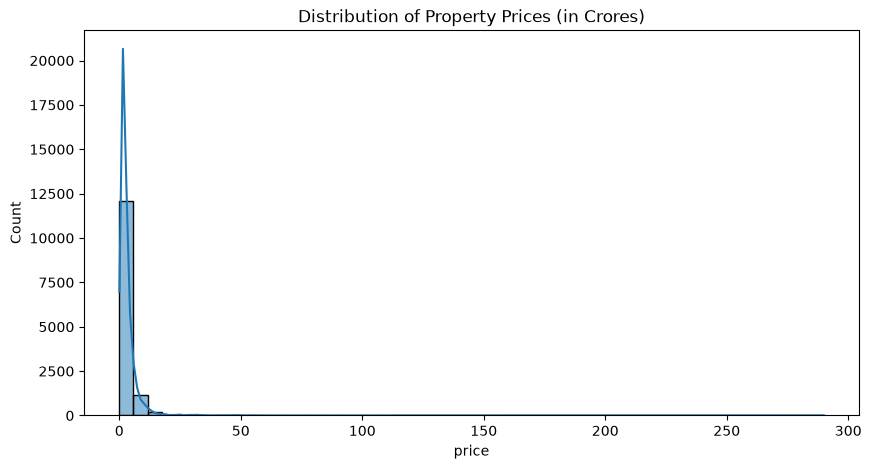

In [778]:
# Outliers on the basis of price column
plt.figure(figsize=(10, 5))
sns.histplot(df['price'], kde=True, bins=50)
plt.title('Distribution of Property Prices (in Crores)')
plt.show()

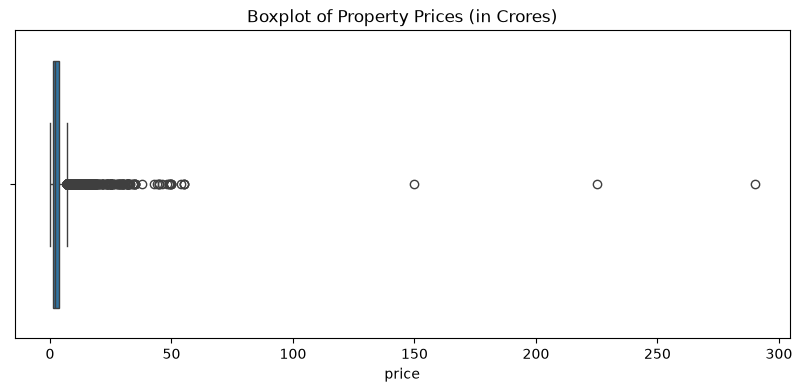

In [779]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price'])
plt.title('Boxplot of Property Prices (in Crores)')
plt.show()

In [780]:
# Calculate the IQR for the 'price' column
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]

# Displaying the number of outliers and some statistics
num_outliers = outliers.shape[0]
outliers_price_stats = outliers['price'].describe()

num_outliers

1052

In [781]:
outliers_price_stats

count    1052.000000
mean       12.577890
std        13.691308
min         6.950000
25%         8.000000
50%         9.600000
75%        12.500000
max       290.000000
Name: price, dtype: float64

In [782]:
outliers.sort_values('price', ascending=False).head(20)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
12108,flat,independent floor at dlf city,sector 24,290.0,2071428.0,1400.0,Built Up area: 2430 (225.75 sq.m.)Carpet area:...,4,4,3,2.0,NaN,New Property,NaN,2430.0,1400.0,0,1,0,0,0,1,193
7930,flat,dlf garden city floors,sector 92,225.0,1190476.0,1890.0,Carpet area: 1890 (175.59 sq.m.),4,4,3+,4.0,North-East,New Property,NaN,NaN,1890.0,0,0,0,0,0,0,60
4176,flat,dlf the camellias,sector 42,150.0,88235.0,17000.0,Super Built up area 17000(1579.35 sq.m.),10,11,3+,38.0,NaN,New Property,17000.0,NaN,NaN,0,1,0,0,0,2,97
5694,flat,dlf the magnolias,sector 42,55.0,43478.0,12650.0,Super Built up area 11500(1068.38 sq.m.),5,6,3+,25.0,North-East,Relatively New,11500.0,NaN,NaN,0,1,0,0,0,2,153
8771,flat,dlf the camellias,sector 42,55.0,74324.0,7400.0,Carpet area: 7400 (687.48 sq.m.),4,4,3+,7.0,North-East,Moderately Old,NaN,NaN,7400.0,0,1,0,0,0,0,213
8463,flat,dlf the camellias,sector 42,55.0,74324.0,7400.0,Super Built up area 7400(687.48 sq.m.),4,8,3+,36.0,North,New Property,7400.0,NaN,NaN,1,1,0,0,0,2,227
10584,flat,elan sector 106,sector 106,54.0,159057.0,3395.0,Super Built up area 3395(315.41 sq.m.)Built Up...,4,4,3+,20.0,East,Under Construction,3395.0,2600.0,NaN,0,0,0,0,0,0,165
7205,flat,dlf the camellias,sector 42,50.0,67851.0,7369.0,Super Built up area 7369(684.60 sq.m.),4,4,3,18.0,North,Moderately Old,7369.0,NaN,NaN,0,1,0,0,0,0,148
11787,flat,dlf the camellias,sector 42,50.0,53835.0,9288.0,Super Built up area 7800(724.64 sq.m.),4,6,3+,3.0,North-East,New Property,7800.0,NaN,NaN,0,0,0,0,0,2,112
11783,flat,dlf the magnolias,sector 42,50.0,46296.0,10800.0,Built Up area: 10800 (1003.35 sq.m.),5,6,3+,23.0,NaN,Moderately Old,NaN,10800.0,NaN,0,0,0,0,0,1,134


In [783]:
# Remove extreme data entry errors in price (290 Cr for 1400 sqft, 225 Cr for 1890 sqft, 54 Cr for 3395 sqft)
price_error_indices = df[
    ((df['price'] > 100) & (df['area'] < 5000)) |
    ((df['society'] == 'elan sector 106') & (df['price'] > 50))
].index

df.drop(index=price_error_indices, inplace=True)

## price_per_sqft

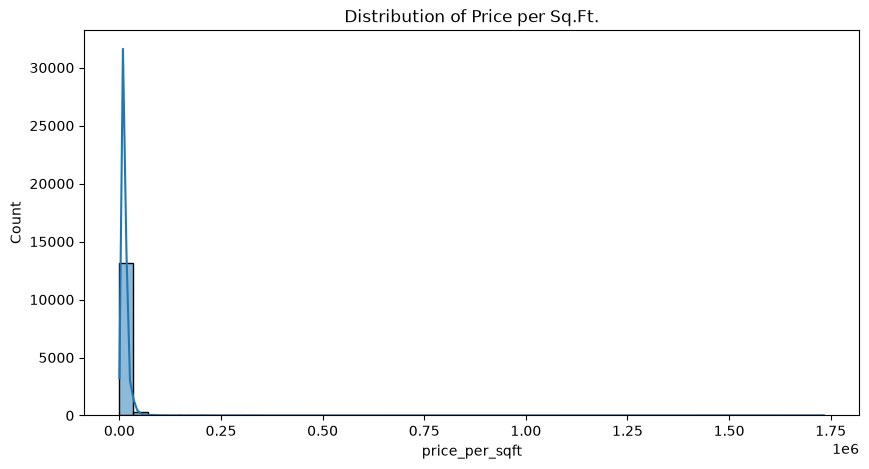

In [784]:
plt.figure(figsize=(10, 5))
sns.histplot(df['price_per_sqft'], kde=True, bins=50)
plt.title('Distribution of Price per Sq.Ft.')
plt.show()

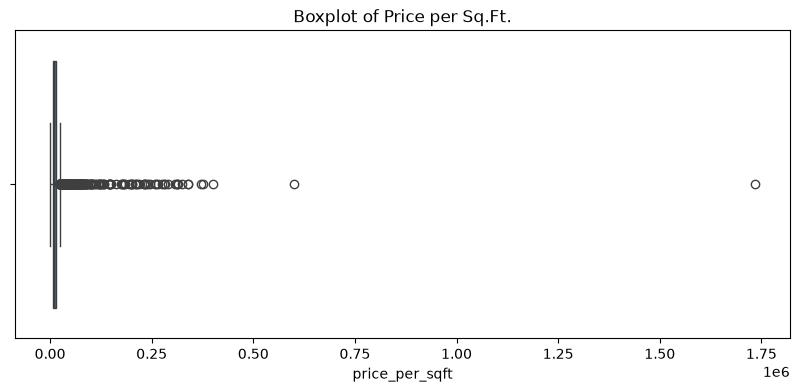

In [785]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price_per_sqft'])
plt.title('Boxplot of Price per Sq.Ft.')
plt.show()

In [786]:
# Calculate the IQR for the 'price_per_sqft' column
Q1 = df['price_per_sqft'].quantile(0.25)
Q3 = df['price_per_sqft'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers (using .copy() to avoid SettingWithCopyWarning)
outliers_sqft = df[(df['price_per_sqft'] < lower_bound) | (df['price_per_sqft'] > upper_bound)].copy()

# Displaying the number of outliers and some statistics
num_outliers = outliers_sqft.shape[0]
outliers_sqft_stats = outliers_sqft['price_per_sqft'].describe()

num_outliers

983

In [787]:
outliers_sqft_stats

count    9.830000e+02
mean     4.885679e+04
std      7.367477e+04
min      2.483200e+04
25%      2.812300e+04
50%      3.333300e+04
75%      4.075900e+04
max      1.733333e+06
Name: price_per_sqft, dtype: float64

In [788]:
## Convert Sq.Yards to Sq.Ft.
outliers_sqft['area'] = outliers_sqft['area'].apply(lambda x: x * 9 if x < 1000 else x)

In [789]:
outliers_sqft['price_per_sqft'] = round((outliers_sqft['price'] * 10000000) / outliers_sqft['area'])

In [790]:
outliers_sqft['price_per_sqft'].describe()

count       983.000000
mean      31224.252289
std       13489.434787
min        2778.000000
25%       26171.500000
50%       31008.000000
75%       36594.000000
max      192593.000000
Name: price_per_sqft, dtype: float64

In [791]:
df.update(outliers_sqft)

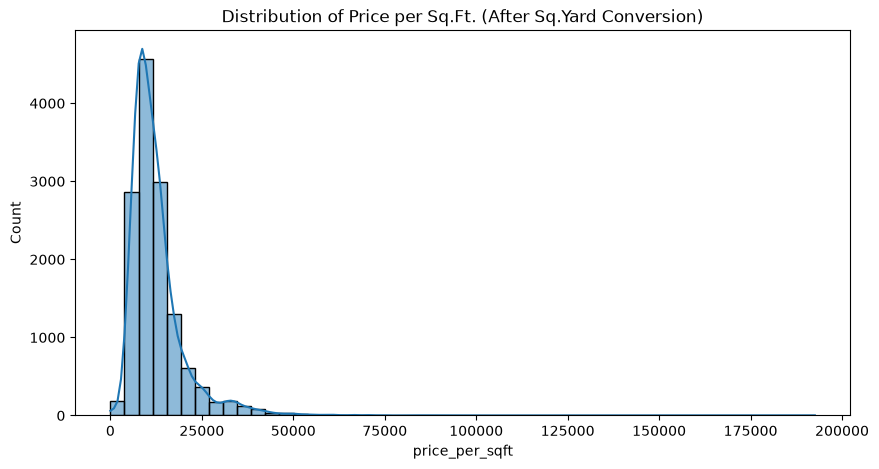

In [792]:
plt.figure(figsize=(10, 5))
sns.histplot(df['price_per_sqft'], kde=True, bins=50)
plt.title('Distribution of Price per Sq.Ft. (After Sq.Yard Conversion)')
plt.show()

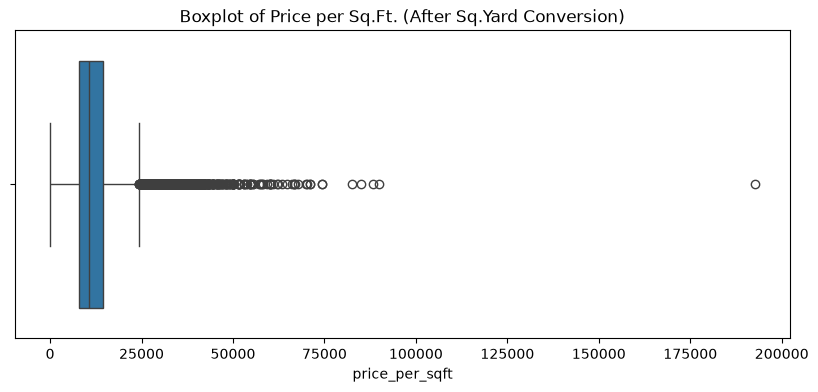

In [793]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price_per_sqft'])
plt.title('Boxplot of Price per Sq.Ft. (After Sq.Yard Conversion)')
plt.show()

In [794]:
df[df['price_per_sqft'] > 50000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
184,house,emaar mgf marbella,sector 66,18.00,55556.0,3240.0,Plot area 360(301.01 sq.m.),4,4,3+,3.0,East,Moderately Old,NaN,3240.0,NaN,1,1,0,1,0,2,103
385,house,nul,sector 28,12.50,51440.0,2430.0,Plot area 270(225.75 sq.m.),16,17,3+,4.0,South,Relatively New,NaN,2430.0,NaN,1,1,0,1,1,2,171
725,house,emaar the palm springs,sector 54,24.00,66667.0,3600.0,Plot area 400(37.16 sq.m.),5,5,2,1.0,North-East,Old Property,NaN,400.0,NaN,1,1,0,1,0,1,144
1166,house,independent,sector 25,16.00,59259.0,2700.0,Plot area 350(292.64 sq.m.)Built Up area: 325 ...,16,16,3+,4.0,West,New Property,NaN,2925.0,2700.0,1,1,1,1,0,1,78
1213,house,project housing board colony,sector 31,8.00,63492.0,1260.0,Built Up area: 140 (117.06 sq.m.),2,1,0,1.0,NaN,Undefined,NaN,1260.0,NaN,0,0,0,0,0,0,0
1244,house,unitech escape,sector 50,10.80,60000.0,1800.0,Plot area 290(242.48 sq.m.)Built Up area: 250 ...,4,4,3,2.0,North,Relatively New,NaN,2250.0,1800.0,1,1,1,1,0,1,125
1299,house,cloudnine cottages,sohna road,5.50,55000.0,1000.0,Plot area 1000(92.9 sq.m.),3,3,0,1.0,NaN,Moderately Old,NaN,1000.0,NaN,0,0,0,0,0,0,0
1395,house,dlf city plots,sector 26,26.00,57206.0,4545.0,Plot area 505(422.24 sq.m.),6,7,3+,2.0,North-East,New Property,NaN,4545.0,NaN,1,1,0,1,1,1,159
1953,house,emaar the palm springs,sector 54,14.00,62222.0,2250.0,Plot area 250(209.03 sq.m.),4,5,3+,2.0,North,Old Property,NaN,2250.0,NaN,1,1,0,0,0,1,199
2806,house,malibu towne,sector 47,8.50,53125.0,1600.0,Built Up area: 1600 (148.64 sq.m.),12,12,3+,4.0,North,New Property,NaN,1600.0,NaN,0,0,0,0,0,1,133


In [795]:
df = df[df['price_per_sqft'] <= 50000].copy()

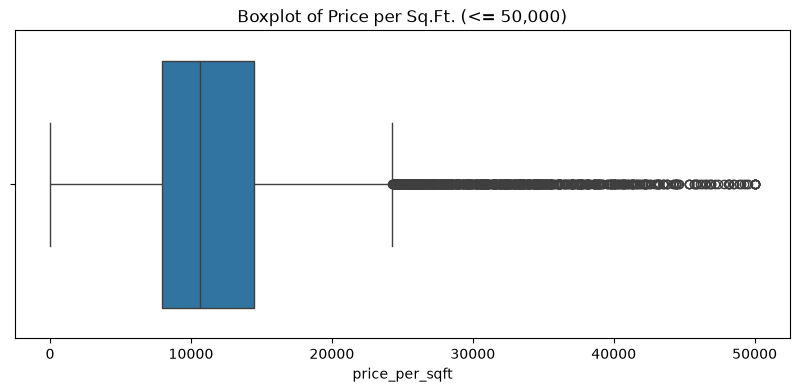

In [796]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['price_per_sqft'])
plt.title('Boxplot of Price per Sq.Ft. (<= 50,000)')
plt.show()

In [797]:
df.shape

(13504, 23)

## area

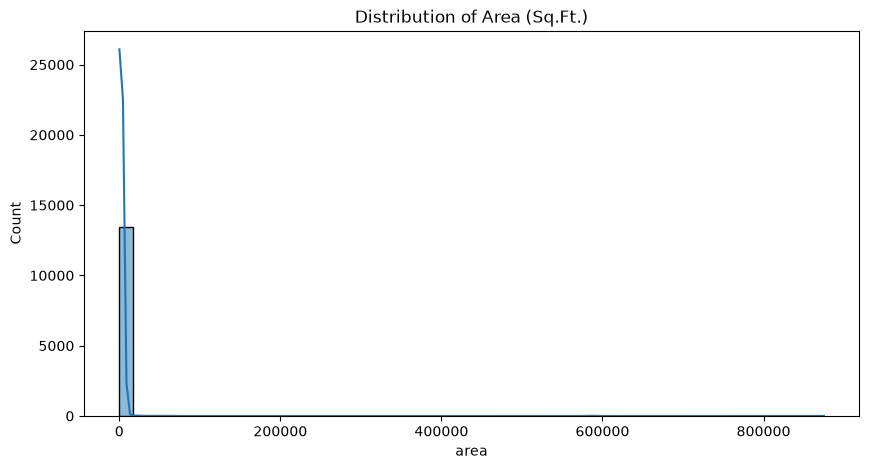

In [798]:
plt.figure(figsize=(10, 5))
sns.histplot(df['area'], kde=True, bins=50)
plt.title('Distribution of Area (Sq.Ft.)')
plt.show()

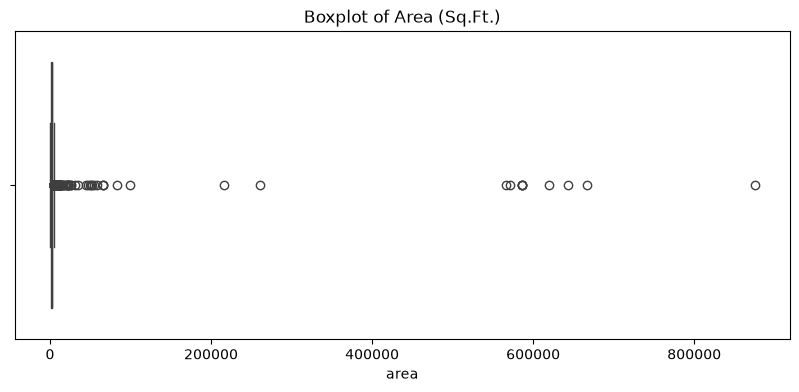

In [799]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['area'])
plt.title('Boxplot of Area (Sq.Ft.)')
plt.show()

In [800]:
df['area'].describe()

count     13504.000000
mean       2789.983560
std       17597.125386
min         145.000000
25%        1450.000000
50%        1950.000000
75%        2690.000000
max      875000.000000
Name: area, dtype: float64

In [801]:
df[df['area'] > 100000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
304,house,independent,sector 50,5.00,232.0,215517.0,Plot area 2(1011.71 sq.m.),6,5,3+,2.0,NaN,New Property,NaN,10890.0,NaN,1,1,0,1,1,1,0
1203,flat,ramsons kshitij,sector 95,0.31,5.0,620000.0,Carpet area: 607936 (56479.1 sq.m.),2,2,1,1.0,North-East,Relatively New,NaN,NaN,607936.0,1,0,0,0,1,0,78
2088,flat,hcbs sports ville,sohna road,0.35,4.0,875000.0,Built Up area: 737147 (68483.2 sq.m.),2,2,2,8.0,NaN,Relatively New,NaN,737147.0,NaN,0,0,0,0,0,2,52
3158,flat,signature global solera 2,sector 107,0.51,9.0,566667.0,Carpet area: 514396 (47788.95 sq.m.),2,2,1,3.0,North,New Property,NaN,NaN,514396.0,0,0,0,0,0,0,52
3371,flat,signature the roselia,sector 95,0.45,7.0,642857.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,2.0,South-West,New Property,NaN,NaN,569243.0,0,0,0,0,0,0,112
5375,flat,signature the roselia,sector 95,0.40,7.0,571429.0,Carpet area: 514272 (47777.43 sq.m.),2,2,2,8.0,North-East,Relatively New,NaN,NaN,514272.0,0,0,0,0,0,0,57
5925,flat,emaar digihomes,sector 62,4.45,171.0,260234.0,Super Built up area 258879(24050.65 sq.m.),3,3,2,28.0,North-East,New Property,258879.0,NaN,NaN,0,0,0,0,0,0,44
6951,flat,signature the roselia,sector 95,0.40,6.0,666667.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,14.0,East,Relatively New,NaN,NaN,569243.0,0,0,1,0,0,0,57
6952,flat,signature the roselia,sector 95,0.41,7.0,585714.0,Carpet area: 569243 (52884.41 sq.m.),2,2,2,10.0,East,Relatively New,NaN,NaN,569243.0,0,0,0,0,0,0,57
6953,flat,signature the roselia,sector 95,0.41,7.0,585714.0,Carpet area: 514272 (47777.43 sq.m.),2,2,2,5.0,East,Relatively New,NaN,NaN,514272.0,0,0,0,0,0,0,57


In [802]:
df = df[df['area'] < 100000].copy()

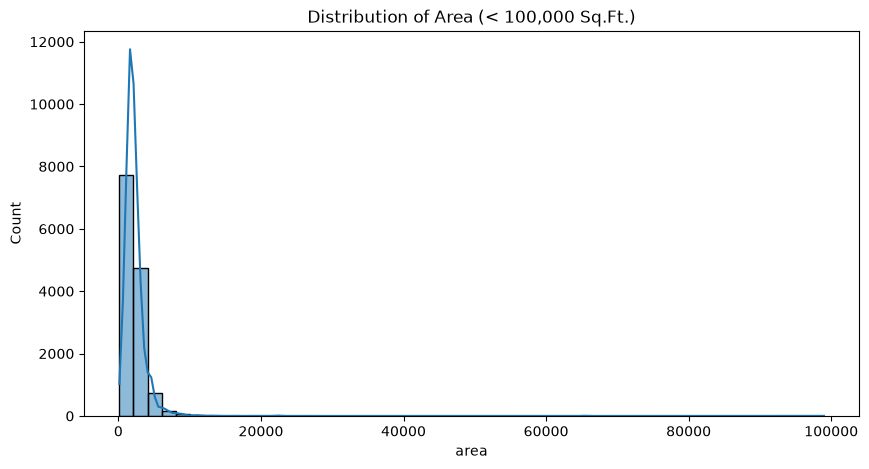

In [803]:
plt.figure(figsize=(10, 5))
sns.histplot(df['area'], kde=True, bins=50)
plt.title('Distribution of Area (< 100,000 Sq.Ft.)')
plt.show()

In [804]:
df[df['area'] > 10000].sort_values('area', ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
1132,house,independent,sector 26,18.40,1859.0,98978.0,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3+,4.0,South,Relatively New,NaN,NaN,99000.00,0,1,1,1,0,1,60
2344,house,ganpati heights apartment,sector 13,1.25,151.0,82781.0,Plot area 115(7692.86 sq.m.),10,6,2,3.0,South-East,Old Property,NaN,82805.0,NaN,0,0,0,0,1,0,13
1624,flat,rof ananda,sector 95,0.38,58.0,65517.0,Carpet area: 64412 (5984.07 sq.m.),3,2,1,12.0,North,Relatively New,NaN,NaN,64412.00,0,0,0,0,0,0,64
302,flat,rof ananda,sector 95,0.38,58.0,65517.0,Carpet area: 64529 (5994.94 sq.m.),2,2,2,10.0,East,New Property,NaN,NaN,64529.00,1,0,0,0,0,0,23
46,house,dlf city plot phase 4,sector 28,13.00,1992.0,65261.0,Carpet area: 7250 (6061.92 sq.m.),10,10,3+,1.0,NaN,Undefined,NaN,NaN,65250.00,0,0,0,0,0,0,0
2590,flat,pyramid elite,sector 86,0.46,79.0,58228.0,Carpet area: 58141 (5401.48 sq.m.),2,2,1,0.0,NaN,Under Construction,NaN,NaN,58141.00,0,0,0,0,0,0,23
3614,flat,rof ananda,sector 95,0.33,60.0,55000.0,Carpet area: 54917 (5101.96 sq.m.),2,2,1,13.0,South-West,Relatively New,NaN,NaN,54917.00,0,0,0,0,0,0,45
7017,flat,pyramid urban homes 2,sector 86,0.48,93.0,51613.0,Carpet area: 51557 (4789.80 sq.m.),2,2,2,10.0,South-East,Relatively New,NaN,NaN,51557.00,0,0,0,0,0,1,57
487,house,independent,sector 51,5.50,1087.0,50598.0,Plot area 5620(4699.04 sq.m.)Built Up area: 82...,8,8,2,3.0,North-East,Relatively New,NaN,74340.0,43740.00,0,0,0,1,0,1,55
1719,flat,signature the serenas,sohna road,0.28,57.0,49123.0,Carpet area: 48811 (4534.69 sq.m.),1,1,2,1.0,North-West,Relatively New,NaN,NaN,48811.00,1,0,0,0,0,0,45


In [805]:
# 1. Drop corrupted rows where area > 10,000 but price_per_sqft < 1,000 (unit errors on budget flats/houses)
corrupted_area_idx = df[(df['area'] > 10000) & (df['price_per_sqft'] < 1000)].index
df.drop(index=corrupted_area_idx, inplace=True)

In [806]:
# 2. Correct specific properties where area was miscalculated from price_per_sqft, using built_up_area / carpet_area
# Ganpati Heights Apartment (Plot area 115 sq.yards = 115 * 9 = 1035 sq.ft.)
mask_ganpati = (df['society'] == 'ganpati heights apartment') & (df['area'] > 10000)
df.loc[mask_ganpati, 'area'] = 115 * 9

In [807]:
# DLF City Plot Phase 4 (Carpet area 7250 sq.ft.)
mask_dlf_p4 = (df['society'] == 'dlf city plot phase 4') & (df['area'] > 10000)
df.loc[mask_dlf_p4, 'area'] = 7250

In [808]:
# Godrej Air (Carpet area 18122 is a decimal typo for 1812.2 sq.ft.)
mask_godrej_air = (df['society'] == 'godrej air') & (df['area'] > 10000)
df.loc[mask_godrej_air, 'area'] = 1812

In [809]:
# Godrej Icon (Carpet area 1175.11 sq.ft.)
mask_godrej_icon = (df['society'] == 'godrej icon') & (df['area'] > 10000)
df.loc[mask_godrej_icon, 'area'] = 1175

In [810]:
# Unitech Aspen Greens (Built up area 2160 sq.ft.)
mask_unitech_aspen = (df['society'] == 'unitech aspen greens') & (df['area'] > 10000)
df.loc[mask_unitech_aspen, 'area'] = 2160

In [811]:
# Independent houses where area > 10,000 and price_per_sqft < 5,500 but valid built_up_area exists
mask_ind_fix = (df['area'] > 10000) & (df['price_per_sqft'] < 5500) & (df['built_up_area'].notna()) & (df['built_up_area'] < 10000)
df.loc[mask_ind_fix, 'area'] = df.loc[mask_ind_fix, 'built_up_area']

In [812]:
# Recalculate price_per_sqft for the corrected rows
recalc_mask = mask_ganpati | mask_dlf_p4 | mask_godrej_air | mask_godrej_icon | mask_unitech_aspen | mask_ind_fix
df.loc[recalc_mask, 'price_per_sqft'] = round((df.loc[recalc_mask, 'price'] * 10000000) / df.loc[recalc_mask, 'area'])

In [813]:
df[df['area'] > 10000].sort_values('area', ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
1132,house,independent,sector 26,18.40,1859.0,98978.0,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3+,4.0,South,Relatively New,NaN,NaN,99000.00,0,1,1,1,0,1,60
487,house,independent,sector 51,5.50,1087.0,50598.0,Plot area 5620(4699.04 sq.m.)Built Up area: 82...,8,8,2,3.0,North-East,Relatively New,NaN,74340.0,43740.00,0,0,0,1,0,1,55
2377,house,independent,sector 25,7.30,1560.0,46795.0,Plot area 215(179.77 sq.m.)Built Up area: 5800...,9,9,2,3.0,North-West,Relatively New,NaN,52200.0,46800.00,0,1,1,0,0,1,130
9407,house,vipul tatvam villa,sector 48,7.75,2460.0,31504.0,Plot area 358(299.33 sq.m.)Built Up area: 3600...,3,5,3+,3.0,North,Old Property,NaN,36000.0,31500.00,0,1,0,0,0,1,190
4814,flat,vatika city,sector 49,3.00,1127.0,26619.0,Super Built up area 26602(2471.41 sq.m.),4,4,3,4.0,North-East,Moderately Old,26602.0,NaN,NaN,0,1,0,0,0,1,171
8458,flat,sushant lok 1 builder floors,sector 43,3.50,1440.0,24306.0,Super Built up area 24300(2257.54 sq.m.),4,4,3,0.0,North-East,New Property,24300.0,NaN,NaN,0,1,0,0,0,2,205
4335,house,independent,sector 43,7.95,3464.0,22950.0,Plot area 30(25.08 sq.m.)Built Up area: 27450 ...,5,5,3+,2.0,West,Moderately Old,NaN,27450.0,22950.00,1,1,0,0,0,2,161
15,house,independent,sector 57,6.25,2778.0,22498.0,Plot area 3100(2591.99 sq.m.)Built Up area: 26...,9,9,3+,3.0,North-East,New Property,NaN,23940.0,22500.00,0,1,0,0,0,1,68
9202,flat,adani brahma samsara vilasa,sector 63,4.20,1867.0,22496.0,Carpet area: 22500 (2090.32 sq.m.),4,4,3+,4.0,North-East,Under Construction,NaN,NaN,22500.00,1,0,0,0,0,2,57
12890,flat,puri emerald bay,sector 104,3.06,1363.0,22450.0,Carpet area: 22450 (2085.67 sq.m.),3,4,3+,15.0,East,Relatively New,NaN,NaN,22450.00,0,1,0,0,0,1,192


In [814]:
df[df['area'] > 30000]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
487,house,independent,sector 51,5.50,1087.0,50598.0,Plot area 5620(4699.04 sq.m.)Built Up area: 82...,8,8,2,3.0,North-East,Relatively New,NaN,74340.0,43740.0,0,0,0,1,0,1,55
1132,house,independent,sector 26,18.40,1859.0,98978.0,Plot area 502(419.74 sq.m.)Carpet area: 11000 ...,6,8,3+,4.0,South,Relatively New,NaN,NaN,99000.0,0,1,1,1,0,1,60
2377,house,independent,sector 25,7.30,1560.0,46795.0,Plot area 215(179.77 sq.m.)Built Up area: 5800...,9,9,2,3.0,North-West,Relatively New,NaN,52200.0,46800.0,0,1,1,0,0,1,130
9407,house,vipul tatvam villa,sector 48,7.75,2460.0,31504.0,Plot area 358(299.33 sq.m.)Built Up area: 3600...,3,5,3+,3.0,North,Old Property,NaN,36000.0,31500.0,0,1,0,0,0,1,190


In [815]:
df = df[df['area'] <= 30000]

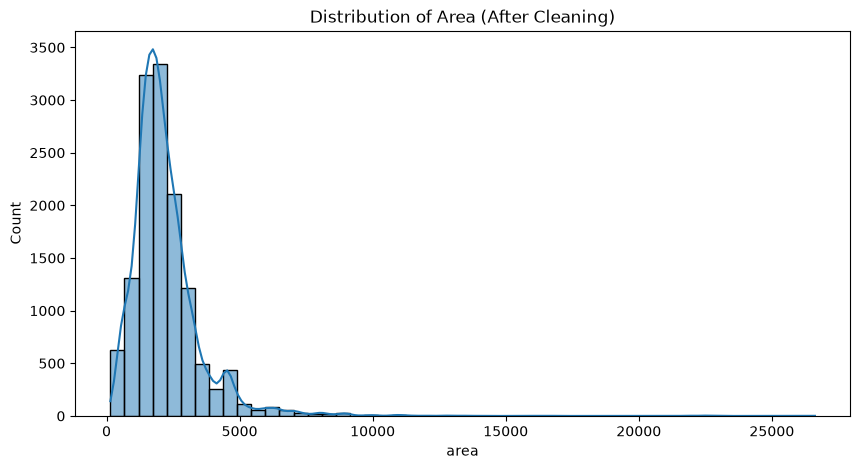

In [816]:
plt.figure(figsize=(10, 5))
sns.histplot(df['area'], kde=True, bins=50)
plt.title('Distribution of Area (After Cleaning)')
plt.show()

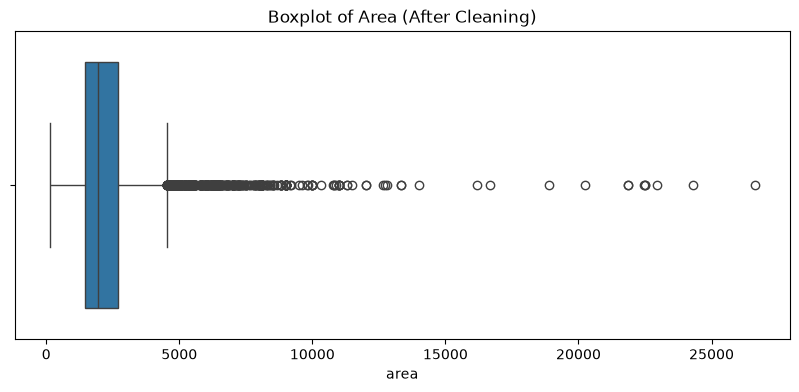

In [817]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['area'])
plt.title('Boxplot of Area (After Cleaning)')
plt.show()

In [818]:
df['area'].describe()

count    13476.000000
mean      2227.531167
std       1383.319020
min        145.000000
25%       1450.000000
50%       1950.000000
75%       2679.250000
max      26619.000000
Name: area, dtype: float64

## bedRoom

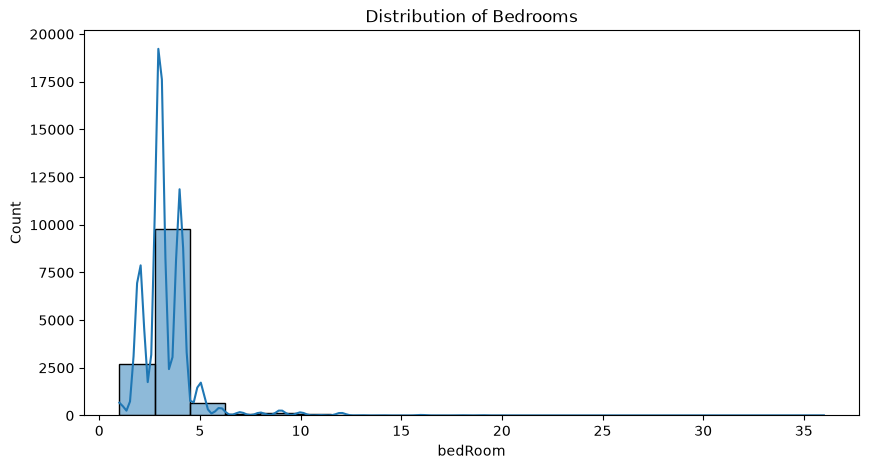

In [819]:
plt.figure(figsize=(10, 5))
sns.histplot(df['bedRoom'], kde=True, bins=20)
plt.title('Distribution of Bedrooms')
plt.show()

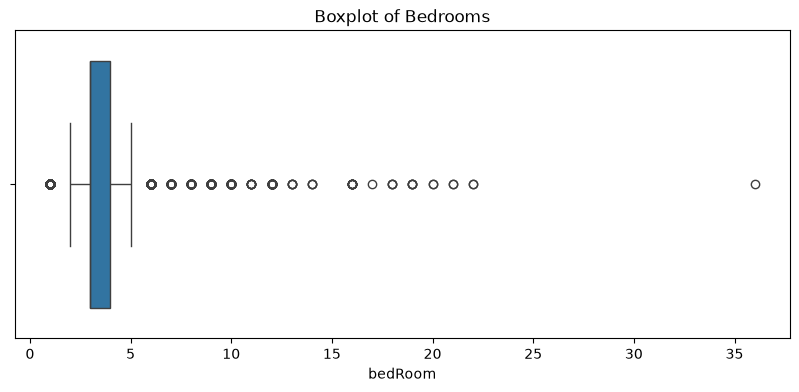

In [820]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['bedRoom'])
plt.title('Boxplot of Bedrooms')
plt.show()

In [821]:
df['bedRoom'].describe()

count    13476.000000
mean         3.327397
std          1.430324
min          1.000000
25%          3.000000
50%          3.000000
75%          4.000000
max         36.000000
Name: bedRoom, dtype: float64

In [822]:
df[df['bedRoom'] > 10].sort_values('bedRoom', ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
3098,house,independent,sector 13,2.25,6944.0,3240.0,Plot area 360(301.01 sq.m.),36,36,2,3.0,East,Moderately Old,NaN,3240.00,NaN,0,1,0,0,0,0,7
9715,house,independent,sector 49,4.25,8745.0,4860.0,Plot area 60(50.17 sq.m.),22,22,3+,5.0,NaN,Relatively New,NaN,540.00,NaN,0,0,0,0,0,0,18
12441,house,independent,sector 43,5.45,10092.0,5400.0,Plot area 600(501.68 sq.m.),22,22,3+,5.0,North,New Property,NaN,5400.00,NaN,0,0,0,0,0,1,63
1398,house,independent,sector 54,5.00,43066.0,1161.0,Plot area 129(107.86 sq.m.),21,21,3+,5.0,North,Relatively New,NaN,1161.00,NaN,0,1,0,0,0,2,55
12442,house,independent,sector 43,5.50,10185.0,5400.0,Plot area 600(501.68 sq.m.),21,21,3+,5.0,North,New Property,NaN,5400.00,NaN,0,1,0,0,0,1,90
7903,house,independent,sector 28,7.50,41667.0,1800.0,Plot area 200(167.23 sq.m.),20,20,3+,4.0,North-East,New Property,NaN,1800.00,NaN,0,0,0,0,0,0,88
176,house,independent,sector 43,4.50,39062.0,1152.0,Plot area 128(107.02 sq.m.),20,20,3+,4.0,East,Relatively New,NaN,1152.00,NaN,0,1,0,0,0,2,28
295,house,independent,sector 17,3.93,24214.0,1623.0,Plot area 1623(150.78 sq.m.)Built Up area: 162...,19,17,3,4.0,North-West,Relatively New,NaN,1622.00,NaN,1,1,1,1,0,0,89
3446,house,independent,sector 17,3.87,5160.0,7500.0,Plot area 1623(150.78 sq.m.)Built Up area: 750...,19,17,3+,5.0,North-West,Relatively New,NaN,7500.00,NaN,1,0,1,0,0,0,85
3806,house,independent,sector 42,10.35,22461.0,4608.0,Plot area 56.89(47.57 sq.m.)Built Up area: 100...,19,19,3+,3.0,South-West,Moderately Old,NaN,10000.00,NaN,0,1,0,0,0,0,79


In [823]:
df = df[df['bedRoom'] <= 10].copy()

In [824]:
df.shape

(13395, 23)

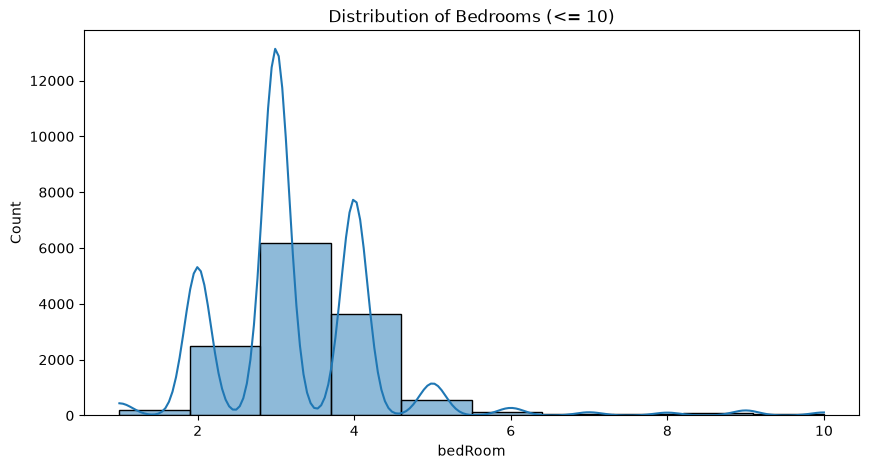

In [825]:
plt.figure(figsize=(10, 5))
sns.histplot(df['bedRoom'], kde=True, bins=10)
plt.title('Distribution of Bedrooms (<= 10)')
plt.show()

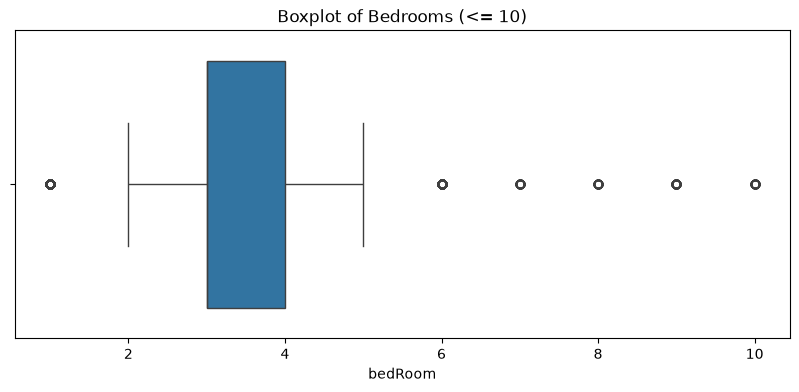

In [826]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['bedRoom'])
plt.title('Boxplot of Bedrooms (<= 10)')
plt.show()

In [827]:
df['bedRoom'].describe()

count    13395.000000
mean         3.262411
std          1.124696
min          1.000000
25%          3.000000
50%          3.000000
75%          4.000000
max         10.000000
Name: bedRoom, dtype: float64

In [828]:
df['area_room_ratio'] = df['area'] / df['bedRoom']

In [829]:
# Inspect abnormally small area-per-bedroom listings
print("Rows with area_room_ratio < 100:", df[df['area_room_ratio'] < 100].shape[0])

Rows with area_room_ratio < 100: 21


In [830]:
# 1. Remove impossible listings where area per bedroom < 100 sq.ft.
df = df[df['area_room_ratio'] >= 100].copy()

In [831]:
# 2. For listings where 100 <= area_room_ratio < 250 and bedRoom > 3, remove anomalous entries
outliers_ratio = df[(df['area_room_ratio'] < 250) & (df['bedRoom'] > 3)]
df.drop(index=outliers_ratio.index, inplace=True)

In [832]:
# Drop temporary helper column if keeping original 23-column schema
df.drop(columns=['area_room_ratio'], inplace=True)

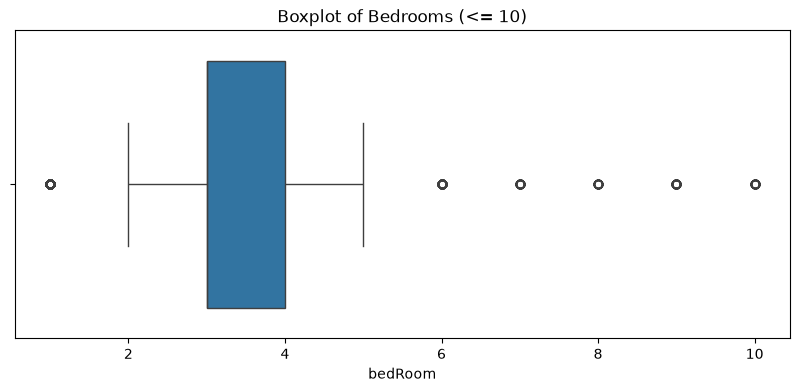

In [833]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['bedRoom'])
plt.title('Boxplot of Bedrooms (<= 10)')
plt.show()

## bathroom

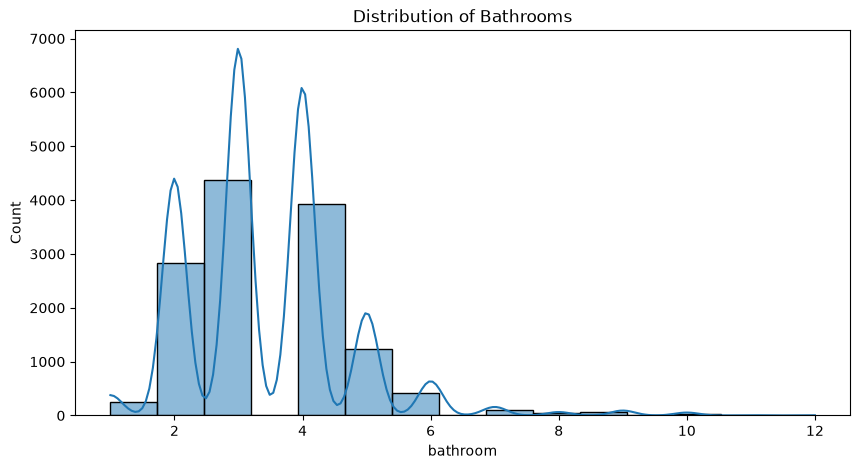

In [834]:
plt.figure(figsize=(10, 5))
sns.histplot(df['bathroom'], kde=True, bins=15)
plt.title('Distribution of Bathrooms')
plt.show()

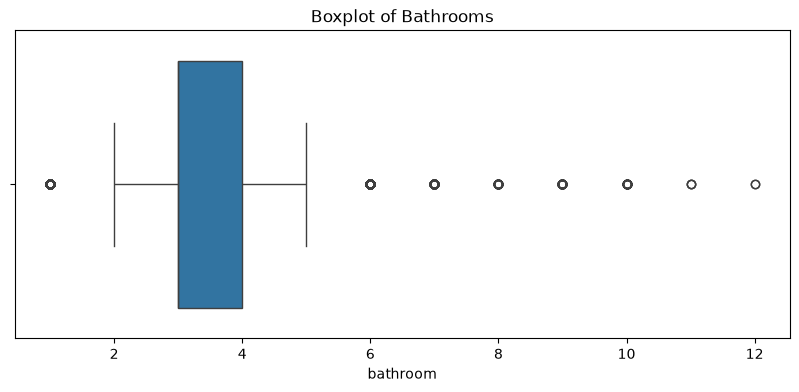

In [835]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['bathroom'])
plt.title('Boxplot of Bathrooms')
plt.show()

In [836]:
df[df['bathroom'] > 10].sort_values('bathroom', ascending=False)

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
2189,house,adani brahma samsara,sector 60,18.02,28200.0,6390.0,Built Up area: 6390 (593.65 sq.m.),9,12,3+,3.0,North-East,Relatively New,NaN,6390.0,NaN,0,1,0,0,0,1,179
12320,house,independent,sector 45,7.00,29573.0,2367.0,Plot area 263(219.90 sq.m.),9,12,3+,3.0,NaN,Relatively New,NaN,2367.0,NaN,0,0,0,0,0,0,55
133,house,independent,sector 24,11.00,28902.0,3806.0,Plot area 3806.45(353.63 sq.m.)Built Up area: ...,8,11,3+,3.0,East,Old Property,NaN,5000.0,NaN,1,1,0,1,1,1,39
909,house,independent,sector 39,7.00,10000.0,7000.0,Plot area 350(32.52 sq.m.)Built Up area: 7000 ...,10,11,3+,4.0,South-East,Relatively New,NaN,7000.0,NaN,0,0,0,1,0,2,38
7498,house,independent,sector 28,10.00,30864.0,3240.0,Plot area 360(301.01 sq.m.),9,11,3+,3.0,NaN,New Property,NaN,3240.0,NaN,1,1,0,0,0,2,55


## super_built_up_area

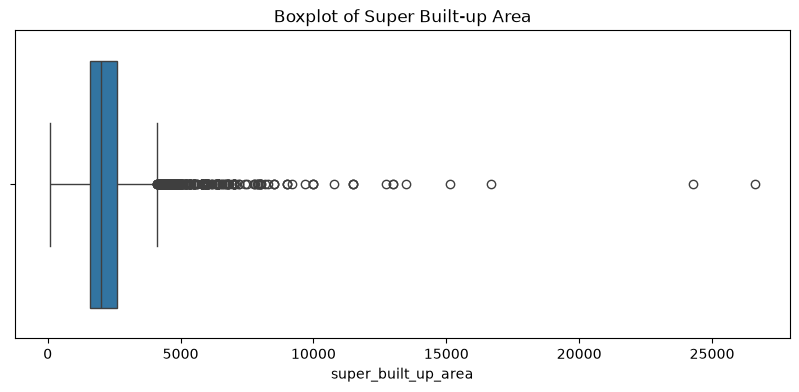

In [837]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['super_built_up_area'])
plt.title('Boxplot of Super Built-up Area')
plt.show()

In [838]:
# Inspect and remove extreme super_built_up_area > 10,000
df = df[(df['super_built_up_area'].isna()) | (df['super_built_up_area'] <= 10000)].copy()

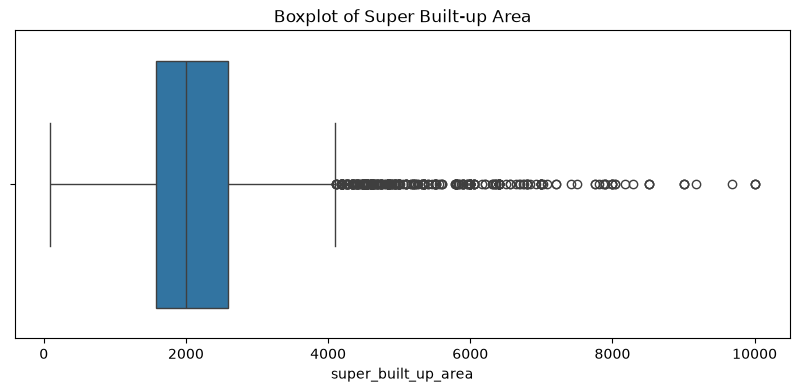

In [839]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['super_built_up_area'])
plt.title('Boxplot of Super Built-up Area')
plt.show()

In [840]:
df.shape

(13233, 23)

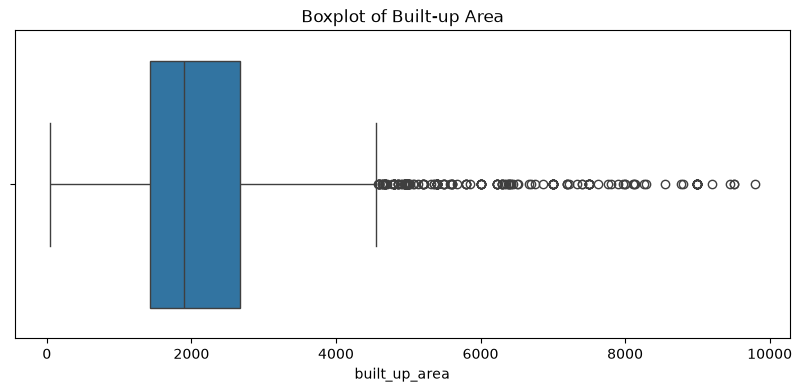

In [841]:
# Remove extreme built_up_area (> 10,000) and carpet_area (> 10,000) anomalies
df = df[(df['built_up_area'].isna()) | (df['built_up_area'] <= 10000)].copy()
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['built_up_area'])
plt.title('Boxplot of Built-up Area')
plt.show()

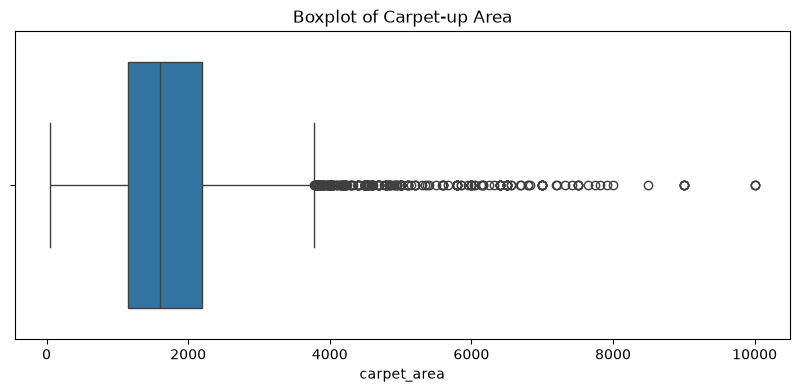

In [842]:
df = df[(df['carpet_area'].isna()) | (df['carpet_area'] <= 10000)].copy()
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['carpet_area'])
plt.title('Boxplot of Carpet-up Area')
plt.show()

In [843]:
df.shape

(13191, 23)

## luxury_score

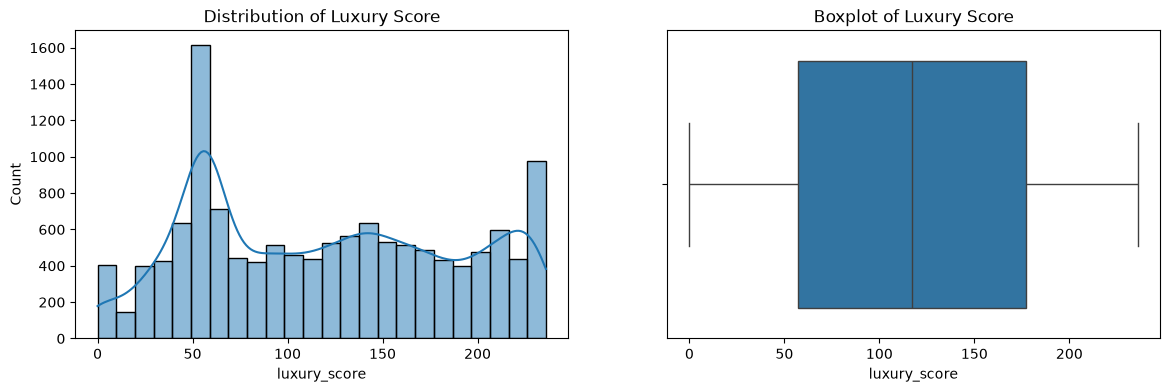

In [844]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['luxury_score'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of Luxury Score')
sns.boxplot(x=df['luxury_score'], ax=axes[1])
axes[1].set_title('Boxplot of Luxury Score')
plt.show()

In [845]:
df.shape

(13191, 23)

In [847]:
df.duplicated().sum()

np.int64(0)

In [846]:
df.to_csv('gurgaon_properties_13k_outlier_treated.csv', index=False)